# Entrega 1 — YOLO customizada

**Autor:** Lucas Carvalho Cordeiro — RM 570388.

**Grupo 21:** Lucas Carvalho Cordeiro — RM 570388; Larissa da Silva Marcelino — RM 571790; Elton Modesto de Souza Dias — RM 572530; Matheus Fontes — RM 570457. **Tutora:** Nicolly Candida.

Nova execução sobre a **base v2**, após substituir quatro cópias redimensionadas de garrafa PET. As medições antigas da Tesla T4 ficam apenas no histórico Git; as células abaixo registram o dispositivo desta execução. Execute na ordem. A base corrigida é baixada da publicação v2. No Colab, o notebook conecta o Drive pessoal e grava numa pasta própria; a nova execução registrada abaixo foi em CPU local.

In [1]:
import os, torch, platform
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
torch.set_num_threads(4)
DISPOSITIVO = '0' if torch.cuda.is_available() else 'cpu'
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else next((s.split(':',1)[1].strip() for s in open('/proc/cpuinfo') if s.startswith('model name')), platform.processor() or 'CPU') if os.path.isfile('/proc/cpuinfo') else platform.processor() or 'CPU'
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__)
print('Dispositivo:', DISPOSITIVO, '| Hardware:', HARDWARE)


Python: 3.12.3 | PyTorch: 2.14.1+cpu
Dispositivo: cpu | Hardware: Intel(R) Core(TM) 7 150U


## 1. Base comum corrigida

As três abordagens usam o mesmo manifesto. São 40 fotos por classe, com 32/4/4. Três substituições estão no treino e uma no teste. As quatro novas caixas foram marcadas manualmente por coordenadas e revisadas visualmente; as outras marcações são as exportadas no Make Sense IA.

Depois de congelar os rótulos, as quatro caixas novas foram importadas, revisadas e exportadas no Make Sense IA em modo offline. O [registro da revisão](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/blob/main/data/revisao_makesense_base_v2.json) informa a diferença de arredondamento do exportador, inferior a 0,001 pixel; os rótulos usados no treino foram preservados.

In [2]:
from pathlib import Path
import os, json, csv, hashlib, zipfile
from urllib.request import urlopen
import yaml

BASE_VERSAO = 'base_v2_sem_duplicatas'
URL_BASE = 'https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/releases/download/base-v2/dataset_farmtech_grupo21_v2.zip'
SHA_ZIP = '120aeffbf4c78e27e69565a5a08bddff73e200dbf38e7acadc685e98b92deb2d'
RAIZ_EXECUCAO = Path('/content') if Path('/content').is_dir() else Path.cwd()
# No Colab, o enunciado pede conexão ao Drive. A pasta v2 pertence ao usuário
# que montar o Drive; não precisamos escrever na pasta compartilhada antiga.
try:
    from google.colab import drive
except ImportError:
    EM_COLAB = False
else:
    EM_COLAB = True
    drive.mount('/content/drive')
RAIZ_ARQUIVOS = Path('/content/drive/MyDrive/FIAP_fase6_grupo21_base_v2') if EM_COLAB else RAIZ_EXECUCAO
RAIZ_ARQUIVOS.mkdir(parents=True, exist_ok=True)
RESULTADOS_PADRAO = RAIZ_ARQUIVOS / 'resultados_farmtech_v2'
BASE = Path(os.environ.get('FARMTECH_DATASET_ROOT', str(RAIZ_ARQUIVOS / 'dataset_yolo/organizado')))

if not (BASE / 'manifesto.csv').is_file():
    BASE.mkdir(parents=True, exist_ok=True)
    pacote = RAIZ_EXECUCAO / 'dataset_farmtech_grupo21_v2.zip'
    print('Baixando a base corrigida, com 80 imagens e suas marcações...')
    with urlopen(URL_BASE, timeout=120) as resposta:
        pacote.write_bytes(resposta.read())
    assert hashlib.sha256(pacote.read_bytes()).hexdigest() == SHA_ZIP, 'ZIP diferente da base publicada.'
    with zipfile.ZipFile(pacote) as z:
        assert all((BASE / f.filename).resolve().is_relative_to(BASE.resolve()) for f in z.infolist())
        z.extractall(BASE)

manifesto = list(csv.DictReader((BASE / 'manifesto.csv').open(newline='')))
assert len(manifesto) == 80
assert len({r['sha256_imagem'] for r in manifesto}) == 80
for r in manifesto:
    imagem = BASE / 'images' / r['conjunto'] / r['arquivo']
    marcacao = BASE / 'labels' / r['conjunto'] / r['marcacao']
    assert hashlib.sha256(imagem.read_bytes()).hexdigest() == r['sha256_imagem'], imagem.name
    linhas = marcacao.read_text().strip().splitlines()
    assert len(linhas) == int(r['quantidade_caixas'])
    for linha in linhas:
        classe, x, y, w, h = map(float, linha.split())
        assert int(classe) == int(r['classe_id']) and 0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1
for conjunto, n in [('train', 32), ('val', 4), ('test', 4)]:
    for classe in [0, 1]:
        assert sum(r['conjunto'] == conjunto and int(r['classe_id']) == classe for r in manifesto) == n
print('Base v2 conferida: 64 treino, 8 validação, 8 teste; 32/4/4 por classe. Imagens verificadas por SHA-256.')
print('Base local:', BASE)


Base v2 conferida: 64 treino, 8 validação, 8 teste; 32/4/4 por classe. Imagens verificadas por SHA-256.
Base local: /tmp/farmtech_base_v2/organizado


## 2. Conferência visual das quatro marcações novas

In [3]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
classes = {0:'banana',1:'garrafa_pet'}
fig, axes = plt.subplots(2,2,figsize=(10,12))
for ax, (split, stem) in zip(axes.flat, [('train','IMG-20261005-WA0108'),('train','IMG-20261005-WA0109'),('train','IMG-20261005-WA0111'),('test','IMG-20261005-WA0112')]):
    foto = ImageOps.exif_transpose(Image.open(BASE/'images'/split/(stem+'.jpg'))).convert('RGB')
    largura, altura = foto.size
    ax.imshow(foto)
    for linha in (BASE/'labels'/split/(stem+'.txt')).read_text().splitlines():
        cid,x,y,w,h = map(float,linha.split())
        ax.add_patch(Rectangle(((x-w/2)*largura,(y-h/2)*altura),w*largura,h*altura,fill=False,edgecolor='lime',linewidth=2))
    ax.set_title(f'{split} — {stem}',fontsize=9);ax.axis('off')
plt.tight_layout();plt.show()


/tmp/ipykernel_260991/2506945005.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout();plt.show()


## 3. Código oficial e pesos iniciais

Fixamos a revisão do YOLOv5 usada na primeira execução. Os dois experimentos começam de forma independente com os pesos COCO da YOLOv5s; nenhum usa o modelo treinado na base antiga.

In [4]:
import subprocess, sys, shutil
YOLO_COMMIT='f9578796b8a64889aa9e66dc06914d19f40d338e'
YOLO = Path(os.environ.get('FARMTECH_YOLO_SOURCE', str(RAIZ_EXECUCAO/'yolov5')))
if not (YOLO/'train.py').is_file():
    subprocess.run(['git','clone','https://github.com/ultralytics/yolov5.git',str(YOLO)],check=True)
    subprocess.run(['git','checkout',YOLO_COMMIT],cwd=YOLO,check=True)
    subprocess.run([sys.executable,'-m','pip','install','-r',str(YOLO/'requirements.txt')],check=True)
assert subprocess.check_output(['git','rev-parse','HEAD'],cwd=YOLO,text=True).strip()==YOLO_COMMIT
PESOS_INICIAIS = YOLO/'yolov5s.pt'
if not PESOS_INICIAIS.is_file():
    subprocess.run([sys.executable,'-c',"from utils.downloads import attempt_download; attempt_download('yolov5s.pt')"],cwd=YOLO,check=True)
print('Commit YOLOv5:',YOLO_COMMIT)
print('SHA-256 pesos iniciais:',hashlib.sha256(PESOS_INICIAIS.read_bytes()).hexdigest())


Commit YOLOv5: f9578796b8a64889aa9e66dc06914d19f40d338e
SHA-256 pesos iniciais: 8b3b748c1e592ddd8868022e8732fde20025197328490623cc16c6f24d0782ee


## 4. Configuração de treino e local das saídas

Mesmo tamanho 640, lote 8, seed 42, cache RAM, duas workers e sem parada antecipada. A quantidade de épocas é a diferença entre os experimentos. O dispositivo é selecionado automaticamente e registrado. Na nova execução em CPU, o lote foi reduzido de 16 para 8 por memória, nos dois experimentos; os resultados da GPU anterior não são misturados.

In [5]:
LOCAL=BASE
DATA=RAIZ_EXECUCAO/'data_farmtech_v2.yaml'
DATA.write_text(yaml.safe_dump({'path':str(LOCAL.resolve()),'train':'images/train','val':'images/val','test':'images/test','nc':2,'names':{0:'banana',1:'garrafa_pet'}},sort_keys=False))
RESULTADOS = Path(os.environ.get('FARMTECH_OUTPUT_ROOT',str(RESULTADOS_PADRAO)))/'yolo_customizada'
RESULTADOS.mkdir(parents=True,exist_ok=True)
ambiente={'base_versao':BASE_VERSAO,'sha256_manifesto':hashlib.sha256((BASE/'manifesto.csv').read_bytes()).hexdigest(),'python':platform.python_version(),'pytorch':torch.__version__,'hardware':HARDWARE,'dispositivo':DISPOSITIVO,'threads_cpu':torch.get_num_threads(),'yolo_commit':YOLO_COMMIT,'imgsz':640,'batch_train':8,'seed':42,'workers':2,'cache':'ram','patience':0,'pesos_iniciais_sha256':hashlib.sha256(PESOS_INICIAIS.read_bytes()).hexdigest()}
(RESULTADOS/'ambiente_execucao.json').write_text(json.dumps(ambiente,ensure_ascii=False,indent=2))
COMANDO_BASE=[sys.executable,str(YOLO/'train.py'),'--data',str(DATA),'--weights',str(PESOS_INICIAIS),'--imgsz','640','--batch-size','8','--device',DISPOSITIVO,'--workers','2','--cache','ram','--seed','42','--patience','0','--project',str(RESULTADOS),'--exist-ok']
print(json.dumps(ambiente,ensure_ascii=False,indent=2))


{
  "base_versao": "base_v2_sem_duplicatas",
  "sha256_manifesto": "a1e2b05d9dccde76b97a04ceee1f983ca7ad987ab0b795e6171eb281227225ba",
  "python": "3.12.3",
  "pytorch": "2.14.1+cpu",
  "hardware": "Intel(R) Core(TM) 7 150U",
  "dispositivo": "cpu",
  "threads_cpu": 4,
  "yolo_commit": "f9578796b8a64889aa9e66dc06914d19f40d338e",
  "imgsz": 640,
  "batch_train": 8,
  "seed": 42,
  "workers": 2,
  "cache": "ram",
  "patience": 0,
  "pesos_iniciais_sha256": "8b3b748c1e592ddd8868022e8732fde20025197328490623cc16c6f24d0782ee"
}


## 5. Treinamento de 30 épocas

In [6]:
import time

def treinar(epocas):
    nome=f'exp_{epocas}_epocas_base_v2'
    pasta=RESULTADOS/nome
    if (pasta/'results.csv').exists():
        raise FileExistsError(f'Use uma pasta de saída nova para não misturar execuções: {pasta}')
    pasta.mkdir(parents=True,exist_ok=True)
    inicio=time.perf_counter()
    with (pasta/'treinamento.log').open('w') as log:
        subprocess.run(COMANDO_BASE+['--epochs',str(epocas),'--name',nome],cwd=YOLO,check=True,stdout=log,stderr=subprocess.STDOUT)
    duracao=time.perf_counter()-inicio
    (pasta/'tempo_execucao.json').write_text(json.dumps({'epocas':epocas,'tempo_execucao_segundos':duracao,'hardware':HARDWARE,'base_versao':BASE_VERSAO},indent=2))
    print(f'Treinamento de {epocas} épocas concluído. Duração: {duracao/60:.2f} min.')
    print('Resultados:',pasta)
    print('\n'.join((pasta/'treinamento.log').read_text().splitlines()[-12:]))
    return pasta,duracao
EXP30,TEMPO30=treinar(30)


Treinamento de 30 épocas concluído. Duração: 23.15 min.
Resultados: /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_30_epocas_base_v2
Optimizer stripped from /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_30_epocas_base_v2/weights/last.pt, 14.4MB
Optimizer stripped from /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_30_epocas_base_v2/weights/best.pt, 14.4MB

Validating /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_30_epocas_base_v2/weights/best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs

                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.3s/it 1.3s
                   all          8         23      0.818      0.653       0.77      0.463
                banana          8         19      0.636      0.632      0.713      0.355
           garrafa_pet          8          4          1      0.674      0.828      0.571
Results saved to /tmp/farmtech_ba

## 6. Treinamento independente de 60 épocas

In [7]:
EXP60,TEMPO60=treinar(60)


Treinamento de 60 épocas concluído. Duração: 42.79 min.
Resultados: /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_60_epocas_base_v2
Optimizer stripped from /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_60_epocas_base_v2/weights/last.pt, 14.4MB
Optimizer stripped from /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_60_epocas_base_v2/weights/best.pt, 14.4MB

Validating /tmp/farmtech_base_v2/resultados/yolo_customizada/exp_60_epocas_base_v2/weights/best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs

                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.3s/it 1.3s
                   all          8         23      0.969      0.705      0.832      0.592
                banana          8         19          1       0.66      0.818      0.491
           garrafa_pet          8          4      0.938       0.75      0.845      0.693
Results saved to /tmp/farmtech_ba

## 7. Validação e escolha antes de usar o teste

Escolhemos o `best.pt` com maior mAP@50–95 na validação. O teste não participa dessa decisão.

In [8]:
import pandas as pd
from IPython.display import display
codigo_avaliacao = r"""
import sys,json
from pathlib import Path
from val import run
pasta=Path(sys.argv[2]);tarefa=sys.argv[3]
metricas,_,_=run(data=sys.argv[1],weights=str(pasta/'weights/best.pt'),task=tarefa,imgsz=640,batch_size=16,device=sys.argv[4],workers=2,project=str(pasta),name='validacao' if tarefa=='val' else 'teste_final',exist_ok=True,verbose=True)
resultado=dict(precisao=float(metricas[0]),recall=float(metricas[1]),map50=float(metricas[2]),map50_95=float(metricas[3]))
(pasta/('metricas_validacao.json' if tarefa=='val' else 'metricas_teste.json')).write_text(json.dumps(resultado,indent=2))
"""
def avaliar(pasta,tarefa):
    with (pasta/f'avaliacao_{tarefa}.log').open('w') as log:
        subprocess.run([sys.executable,'-c',codigo_avaliacao,str(DATA),str(pasta),tarefa,DISPOSITIVO],cwd=YOLO,check=True,stdout=log,stderr=subprocess.STDOUT)
    return json.loads((pasta/('metricas_validacao.json' if tarefa=='val' else 'metricas_teste.json')).read_text())
linhas=[]
for epocas,pasta,tempo in [(30,EXP30,TEMPO30),(60,EXP60,TEMPO60)]:
    m=avaliar(pasta,'val')
    linhas.append({'Épocas':epocas,'Precisão (%)':m['precisao']*100,'Recall (%)':m['recall']*100,'mAP@50 (%)':m['map50']*100,'mAP@50–95 (%)':m['map50_95']*100,'Duração (min)':tempo/60})
comparacao=pd.DataFrame(linhas)
comparacao.to_csv(RESULTADOS/'comparacao_validacao_yolo.csv',index=False)
display(comparacao.round(2))
ESCOLHIDO=int(comparacao.sort_values('mAP@50–95 (%)',ascending=False).iloc[0]['Épocas'])
EXP_ESCOLHIDO=EXP30 if ESCOLHIDO==30 else EXP60
MODELO_ESCOLHIDO=EXP_ESCOLHIDO/'weights/best.pt'
(RESULTADOS/'selecao_modelo.json').write_text(json.dumps({'epocas_escolhidas':ESCOLHIDO,'criterio':'maior mAP@50-95 de validação','modelo':str(MODELO_ESCOLHIDO),'base_versao':BASE_VERSAO},ensure_ascii=False,indent=2))
print('Escolhido na validação:',ESCOLHIDO,'épocas.')


,Épocas,Precisão (%),Recall (%),mAP@50 (%),mAP@50–95 (%),Duração (min)
0,30,81.67,65.38,77.05,46.30,23.15
1,60,96.90,70.49,83.16,59.19,42.79


Escolhido na validação: 60 épocas.


## 8. Teste reservado — oito imagens

Precisão, recall e mAP medem detecção. A comparação com a CNN usará outra medida: acerto da classe por foto.

In [9]:
metricas_teste=avaliar(EXP_ESCOLHIDO,'test')
resultado_teste=pd.DataFrame([{'Modelo':f'YOLOv5s — {ESCOLHIDO} épocas, base v2','Precisão (%)':metricas_teste['precisao']*100,'Recall (%)':metricas_teste['recall']*100,'mAP@50 (%)':metricas_teste['map50']*100,'mAP@50–95 (%)':metricas_teste['map50_95']*100}])
resultado_teste.to_csv(RESULTADOS/'resultado_teste_yolo.csv',index=False)
TESTE=EXP_ESCOLHIDO/'teste_final'
display(resultado_teste.round(2))


,Modelo,Precisão (%),Recall (%),mAP@50 (%),mAP@50–95 (%)
0,"YOLOv5s — 60 épocas, base v2",89.28,72.84,78.53,51.95


## 9. Imagens processadas e erros

Marcações reais


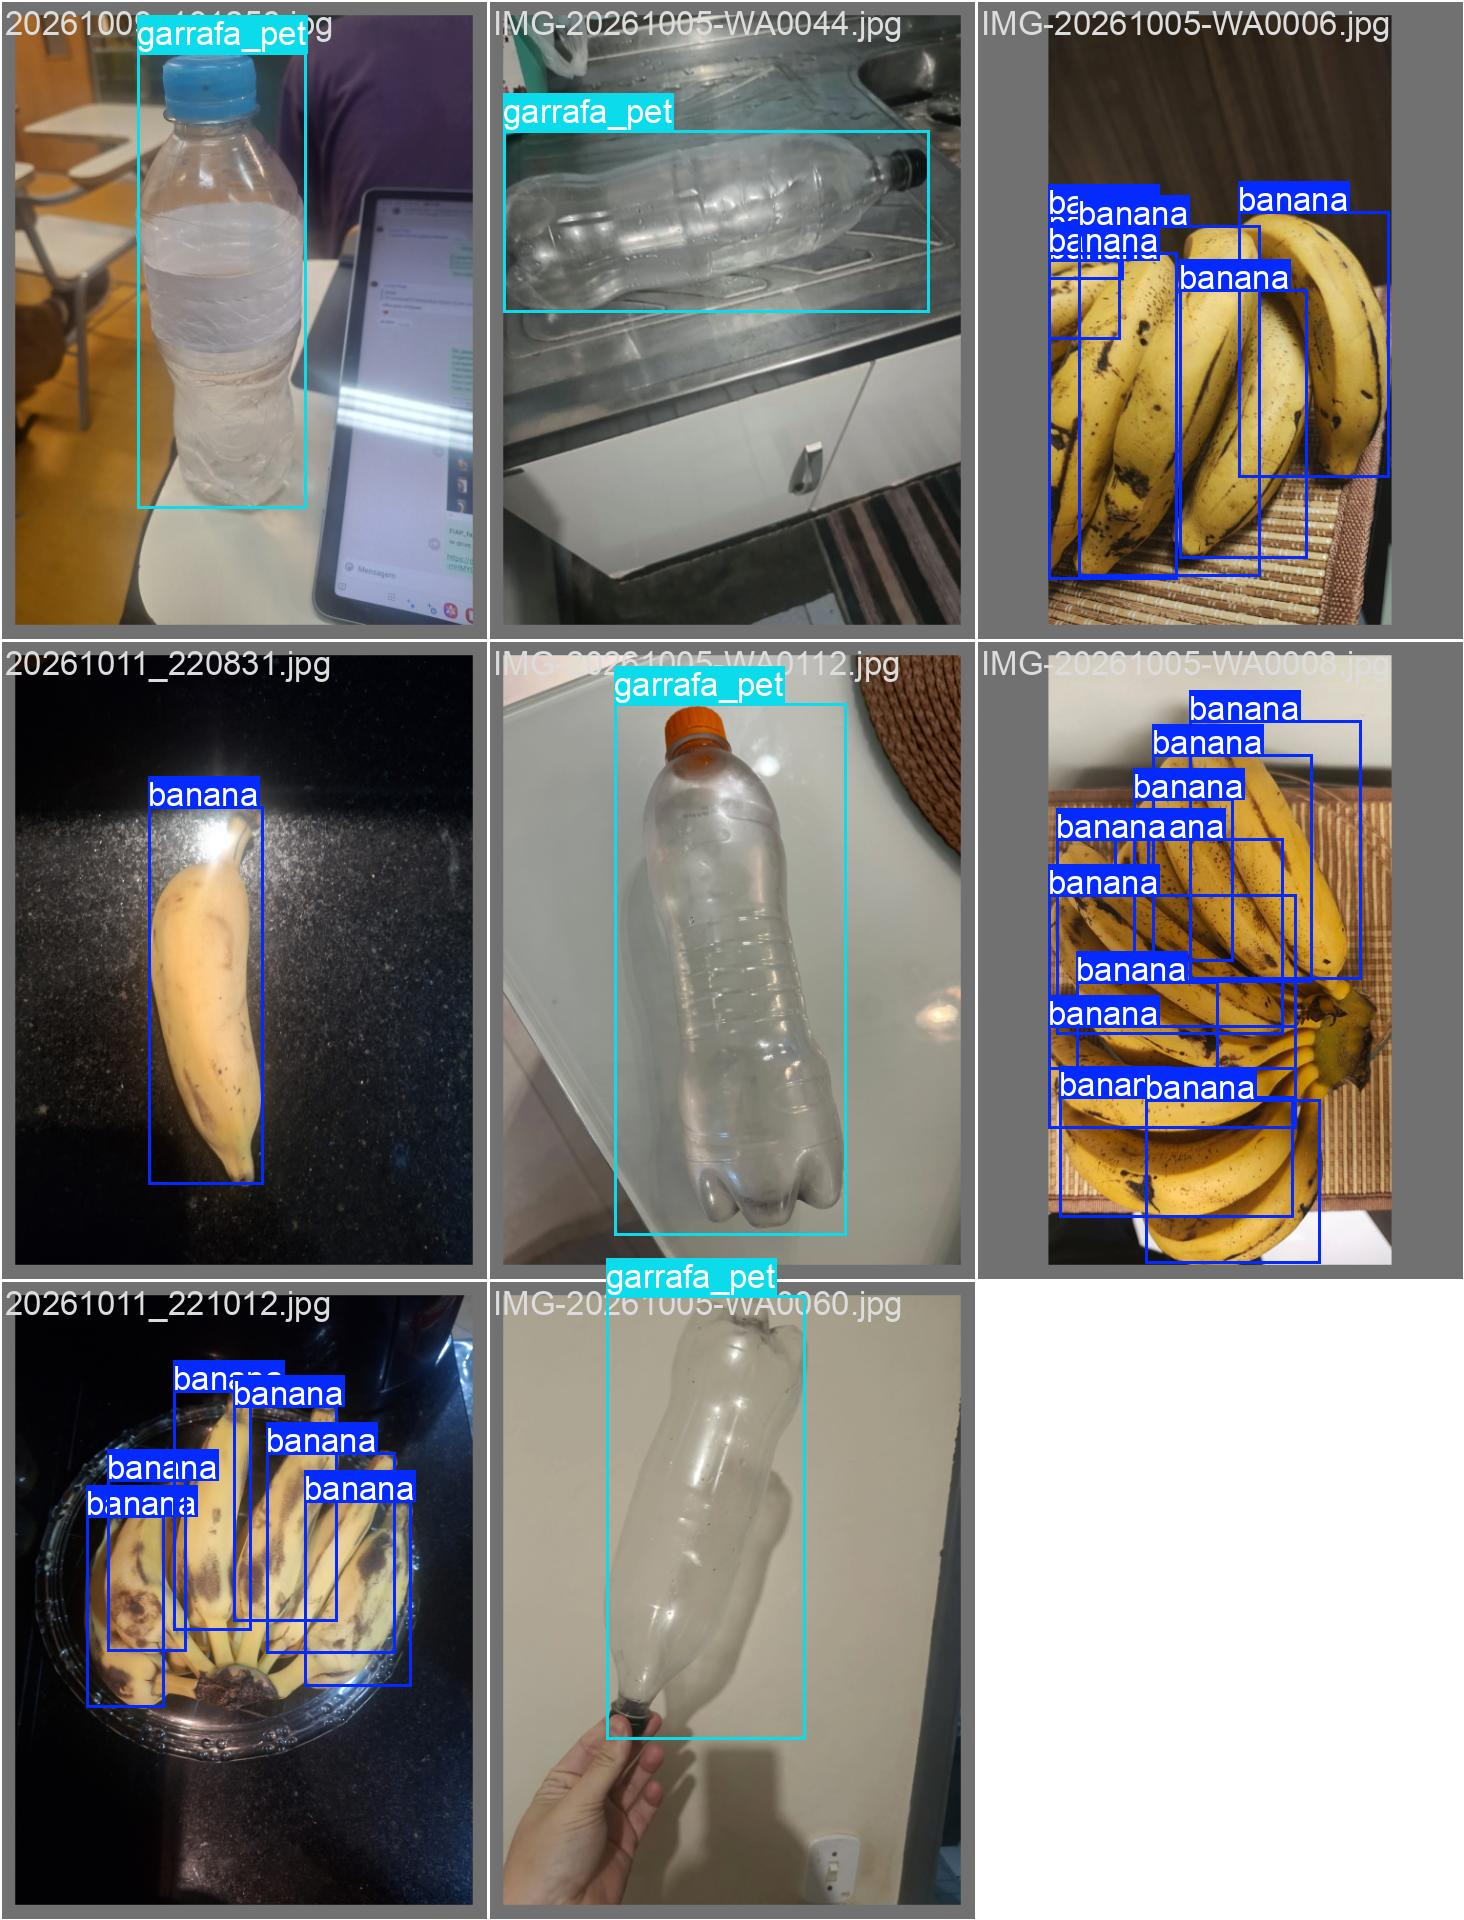

Previsões da YOLO


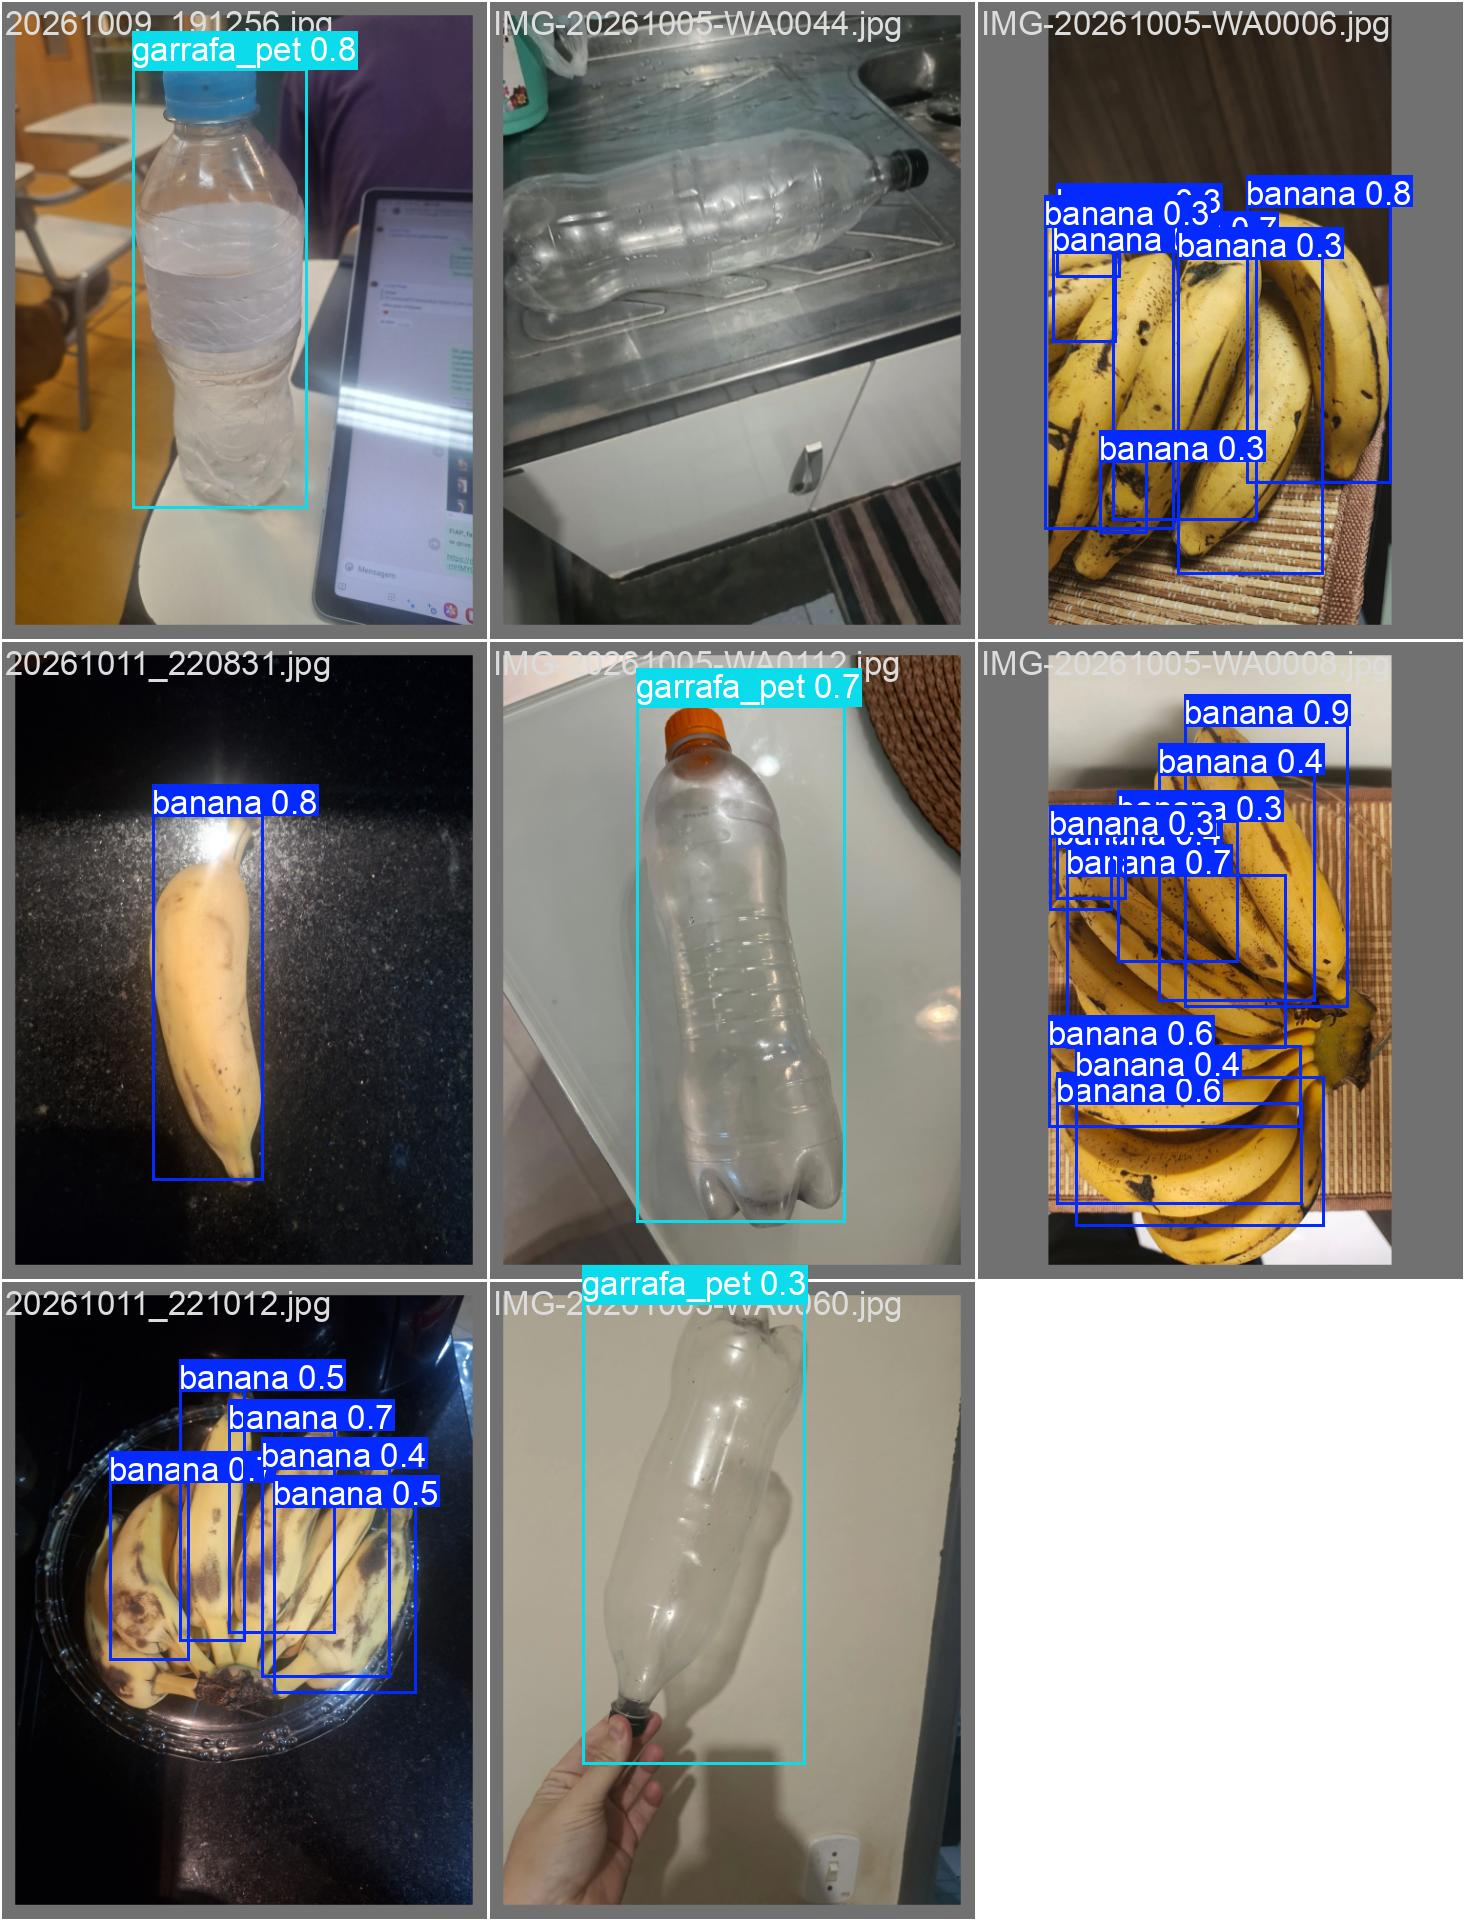

Matriz de confusão


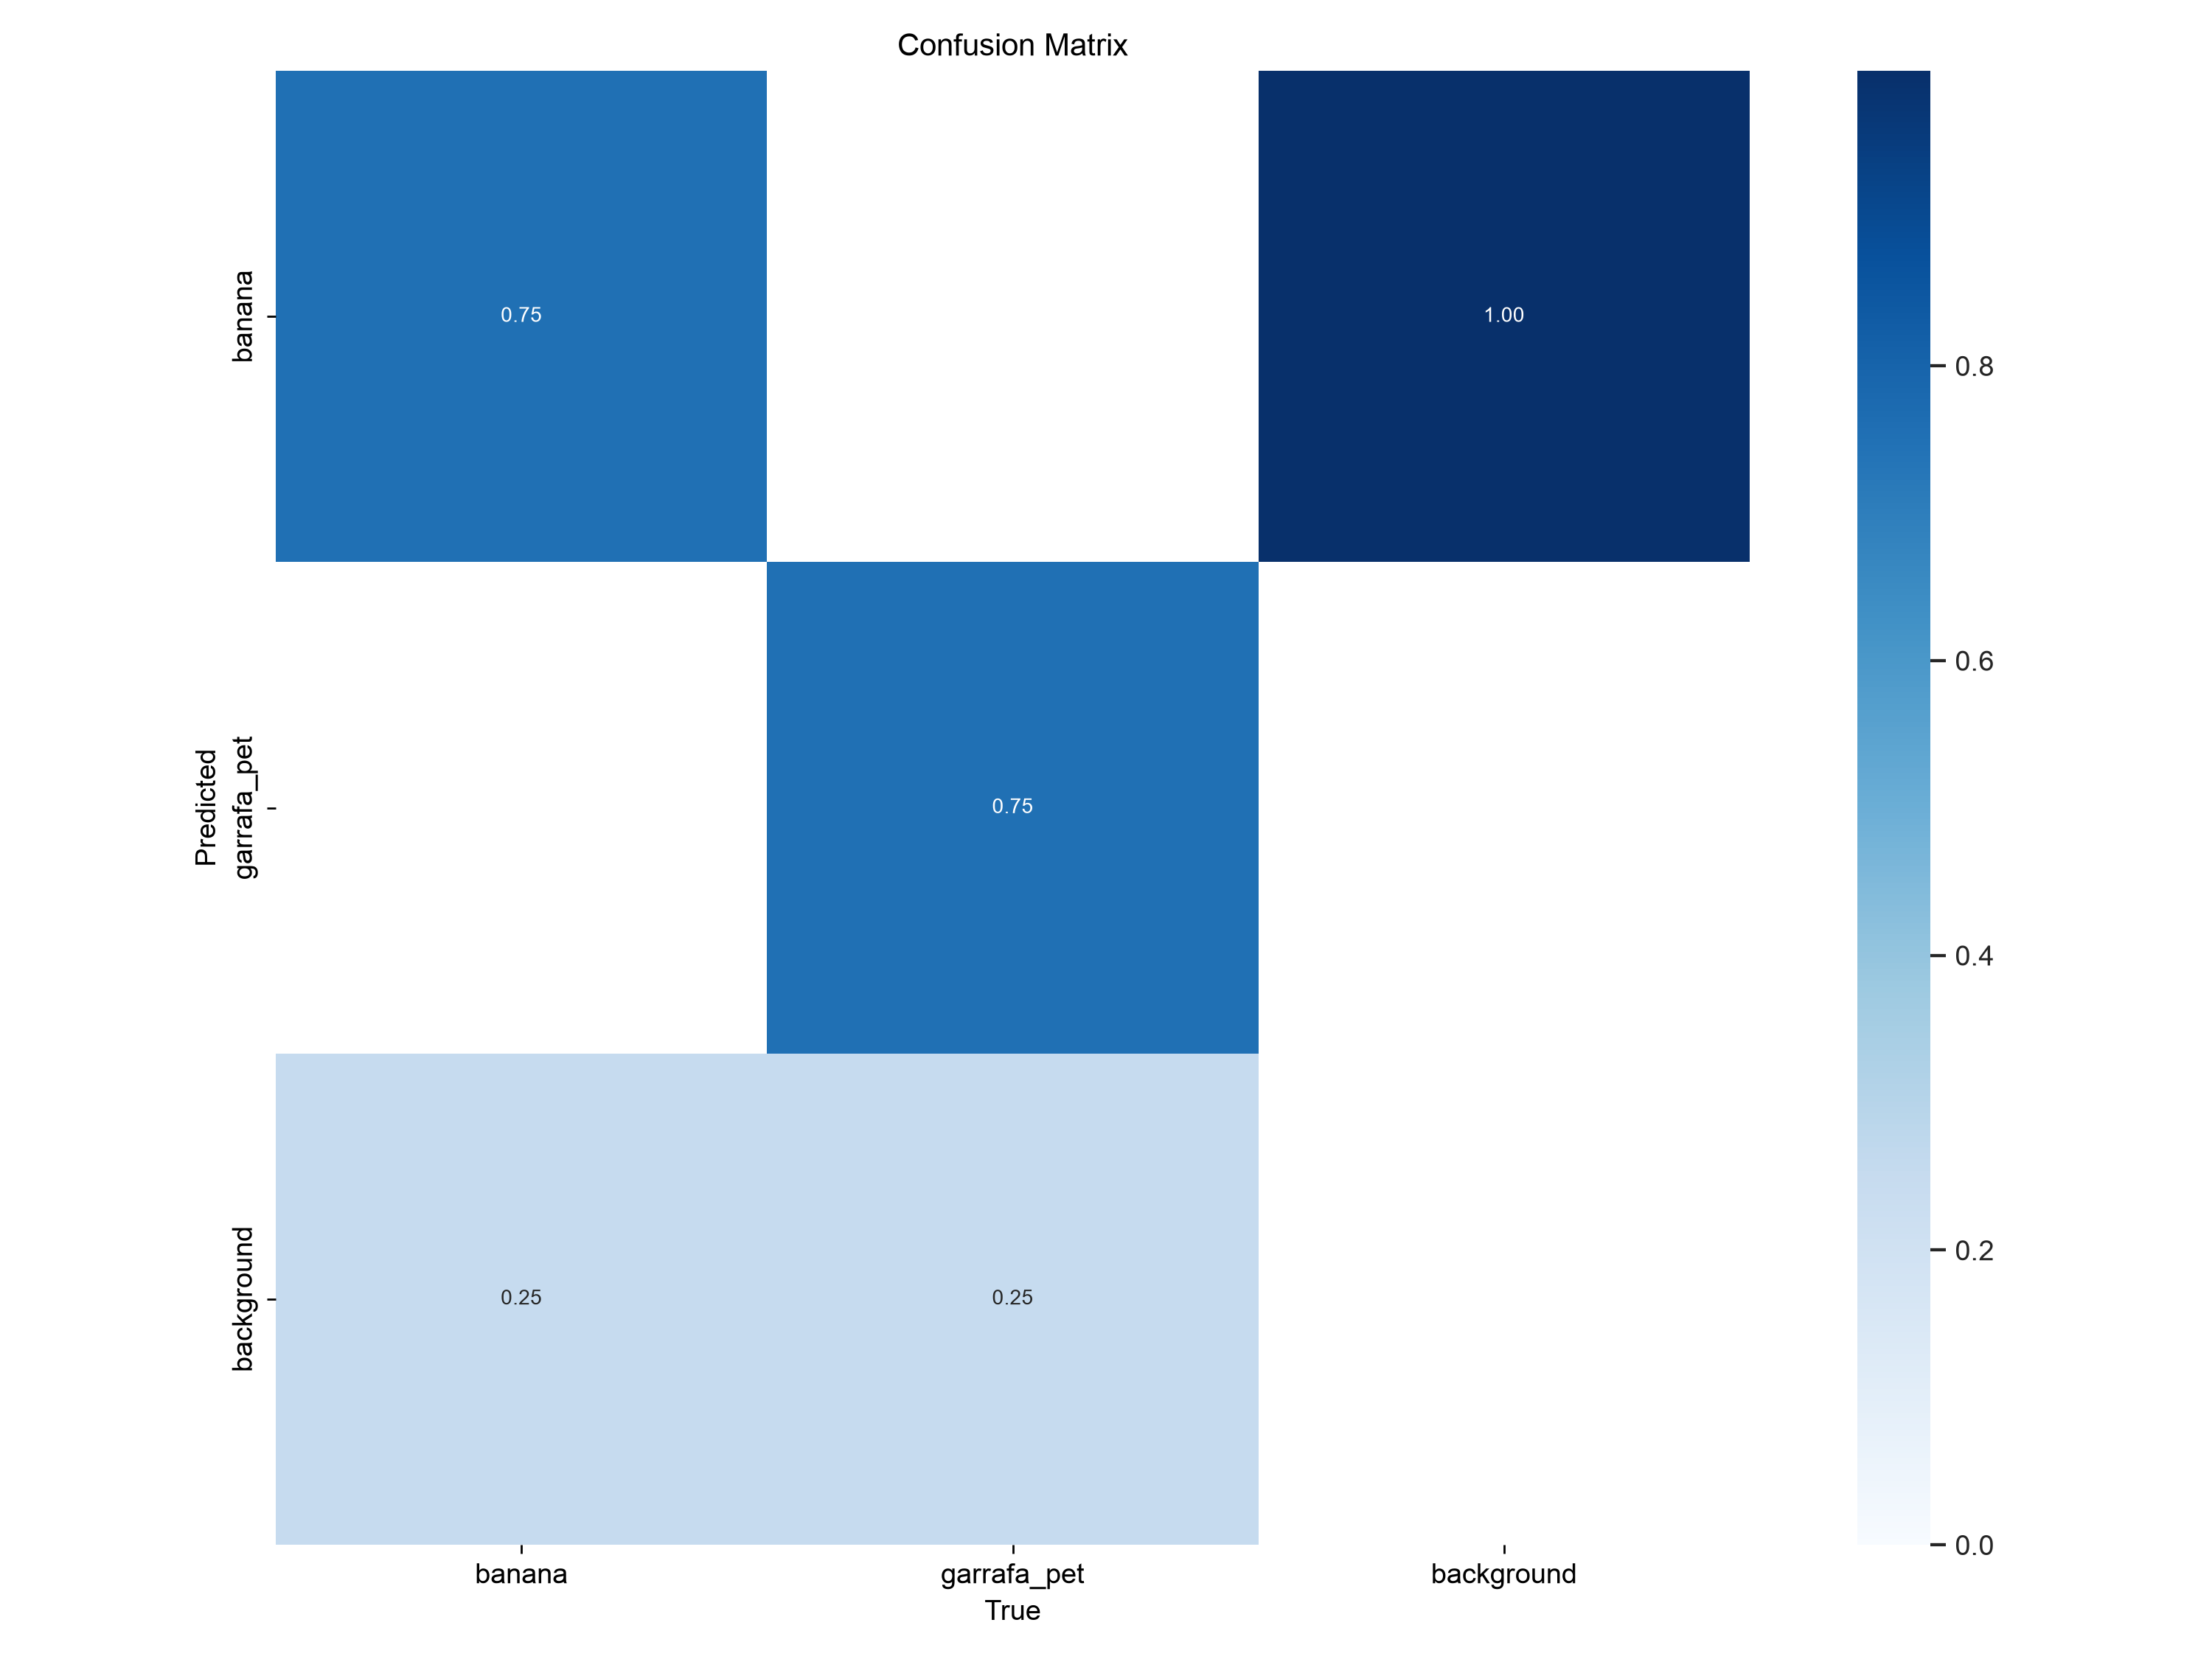

In [10]:
from IPython.display import Image as Imagem
for titulo,nome in [('Marcações reais','val_batch0_labels.jpg'),('Previsões da YOLO','val_batch0_pred.jpg'),('Matriz de confusão','confusion_matrix.png')]:
    print(titulo)
    display(Imagem(filename=str(TESTE/nome),width=1000))


## 10. Acerto por foto

Confiança mínima 0,25, IoU NMS 0,60; escolhemos a classe da caixa de maior confiança. Ausência de detecção conta como erro. As caixas salvas são previsões reais.

In [11]:
PREDICOES=EXP_ESCOLHIDO/'predicoes_por_foto_base_v2'
execucao=subprocess.run([sys.executable,str(YOLO/'detect.py'),'--weights',str(MODELO_ESCOLHIDO),'--source',str(LOCAL/'images/test'),'--imgsz','640','--conf-thres','0.25','--iou-thres','0.60','--max-det','300','--classes','0','1','--device',DISPOSITIVO,'--save-txt','--save-conf','--project',str(EXP_ESCOLHIDO),'--name',PREDICOES.name,'--exist-ok'],cwd=YOLO,text=True,capture_output=True)
LOG_INFERENCIA=execucao.stdout+'\n'+execucao.stderr
if execucao.returncode:
    print(LOG_INFERENCIA);execucao.check_returncode()
(PREDICOES/'log_inferencia.txt').write_text(LOG_INFERENCIA)
linhas=[]
for foto in sorted((LOCAL/'images/test').glob('*.jpg')):
    reais={int(s.split()[0]) for s in (LOCAL/'labels/test'/f'{foto.stem}.txt').read_text().splitlines() if s.strip()}
    assert len(reais)==1
    real=reais.pop();p=PREDICOES/'labels'/f'{foto.stem}.txt'
    deteccoes=[s.split() for s in p.read_text().splitlines() if s.strip()] if p.is_file() else []
    previsto=int(max(deteccoes,key=lambda d:float(d[-1]))[0]) if deteccoes else None
    linhas.append({'Foto':foto.name,'Esperado':classes[real],'Previsto':classes.get(previsto,'Sem detecção'),'Acertou':'Sim' if previsto==real else 'Não','sha256_imagem':hashlib.sha256(foto.read_bytes()).hexdigest()})
tabela_fotos=pd.DataFrame(linhas);acertos=int(tabela_fotos['Acertou'].eq('Sim').sum())
tabela_fotos.to_csv(PREDICOES/'acertos_por_foto.csv',index=False)
display(tabela_fotos)
print(f'Acerto por foto: {acertos}/8 = {100*acertos/8:.2f}%')


,Foto,Esperado,Previsto,Acertou,sha256_imagem
0,20261009_191256.jpg,garrafa_pet,garrafa_pet,Sim,9937ada70178bc731201993af79996e1b748deb3b1cb5d...
1,20261011_220831.jpg,banana,banana,Sim,94e4fae57f70a3e6cf7793e53cfd35117e9297447aa5e6...
2,20261011_221012.jpg,banana,banana,Sim,7a92277952f6c3696e7479612b5d5ddbe30b69d9315a8a...
3,IMG-20261005-WA0006.jpg,banana,banana,Sim,e915f8e8312a470324a3b29c4e21e91e1f19f7edb2b874...
4,IMG-20261005-WA0008.jpg,banana,banana,Sim,da6926d3062f0bbb7e1e11f3aaa9a83265b2bc3b33e5f5...
5,IMG-20261005-WA0044.jpg,garrafa_pet,Sem detecção,Não,3b028f57e6ffc49be78511ee951fec1807cc32a8840674...
6,IMG-20261005-WA0060.jpg,garrafa_pet,garrafa_pet,Sim,38a73d472f49ecad34ebe1835857e88c6e31f4382f8fb2...
7,IMG-20261005-WA0112.jpg,garrafa_pet,garrafa_pet,Sim,3afde1b734b9decb9e8fb29fad3aeae6c4eddd90e6ea09...


Acerto por foto: 7/8 = 87.50%


## 11. Tempos e limites da comparação

O `detect.py` separa preparo do tensor, cálculo da rede e NMS. Leitura completa da foto, carregamento de pesos e gravação das imagens não estão incluídos.

In [12]:
import re
medicao=re.search(r'Speed:\s*([\d.]+)ms pre-process,\s*([\d.]+)ms inference,\s*([\d.]+)ms NMS',LOG_INFERENCIA)
if medicao is None:raise ValueError(LOG_INFERENCIA)
preparacao_ms,modelo_ms,filtragem_ms=map(float,medicao.groups())
tempos={'preparacao_medida_ms_por_foto':preparacao_ms,'inferencia_modelo_ms_por_foto':modelo_ms,'filtragem_caixas_ms_por_foto':filtragem_ms,'fotos_avaliadas':8,'hardware':HARDWARE,'dispositivo':DISPOSITIVO,'batch_size':1,'imgsz':640,'base_versao':BASE_VERSAO}
(PREDICOES/'tempos_inferencia.json').write_text(json.dumps(tempos,ensure_ascii=False,indent=2))
resumo={'base_versao':BASE_VERSAO,'epocas_escolhidas':ESCOLHIDO,'acertos':acertos,'fotos_teste':8,'acuracia_por_imagem':acertos/8,'metricas_teste':metricas_teste,'tempo_treinamento_s':TEMPO30 if ESCOLHIDO==30 else TEMPO60,'tempos':tempos,'ambiente':ambiente,'fonte_acertos':str(PREDICOES/'acertos_por_foto.csv'),'pesos_sha256':hashlib.sha256(MODELO_ESCOLHIDO.read_bytes()).hexdigest()}
(RESULTADOS/'resumo_yolo_customizada.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2))
print(json.dumps(resumo,ensure_ascii=False,indent=2))


{
  "base_versao": "base_v2_sem_duplicatas",
  "epocas_escolhidas": 60,
  "acertos": 7,
  "fotos_teste": 8,
  "acuracia_por_imagem": 0.875,
  "metricas_teste": {
    "precisao": 0.8928375998470715,
    "recall": 0.7284286450953117,
    "map50": 0.7852978383293475,
    "map50_95": 0.5194863646210319
  },
  "tempo_treinamento_s": 2567.1364446080115,
  "tempos": {
    "preparacao_medida_ms_por_foto": 0.7,
    "inferencia_modelo_ms_por_foto": 169.7,
    "filtragem_caixas_ms_por_foto": 1.1,
    "fotos_avaliadas": 8,
    "hardware": "Intel(R) Core(TM) 7 150U",
    "dispositivo": "cpu",
    "batch_size": 1,
    "imgsz": 640,
    "base_versao": "base_v2_sem_duplicatas"
  },
  "ambiente": {
    "base_versao": "base_v2_sem_duplicatas",
    "sha256_manifesto": "a1e2b05d9dccde76b97a04ceee1f983ca7ad987ab0b795e6171eb281227225ba",
    "python": "3.12.3",
    "pytorch": "2.14.1+cpu",
    "hardware": "Intel(R) Core(TM) 7 150U",
    "dispositivo": "cpu",
    "threads_cpu": 4,
    "yolo_commit": "f957879

## 12. Conclusão

A validação selecionou o experimento de **60 épocas**. No teste reservado, a YOLO obteve **7/8 classes corretas**, mAP@50 de **78,53%** e mAP@50–95 de **51,95%**. Acurácia por foto e mAP são medidas diferentes: uma classe correta não garante que todos os objetos receberam caixas adequadas.

Os dois treinos foram realmente refeitos na base v2, em CPU, com lote 8. Os tempos antigos da Tesla T4 não foram reutilizados. A nova versão remove quatro cópias; oito fotos de teste ainda são poucas para concluir generalização. Cenas semelhantes e o mesmo objeto físico em diferentes fotos podem favorecer o resultado.

A [Entrega 2](https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/blob/main/EltonModestoDeSouzaDias_rm572530_pbl_fase6.ipynb) compara as três abordagens no mesmo teste, com previsões individuais e condições de medição.

**Falha observada:** `IMG-20261005-WA0044.jpg` ficou sem detecção a partir de 0,25. A foto mostra uma garrafa transparente deitada sobre uma superfície metálica com reflexos. São condições a investigar em novas coletas, sem concluir uma causa específica a partir de uma única imagem.